# Proyecto KDD: optimización de estrategias de ventas en Amazon

**Dataset:** Amazon Sales Dataset  
**Objetivo:** Aplicar el proceso KDD completo (selección, limpieza, transformación, minería de datos e interpretación) para extraer insights y recomendar estrategias de ventas y marketing.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 4)

print('Librerías cargadas correctamente.')
%config InlineBackend.figure_format = 'retina'

Librerías cargadas correctamente.


## Fase 1: Selección de datos

Cargamos el dataset y hacemos una exploración inicial para entender qué columnas son relevantes para nuestro análisis de estrategias de ventas.

In [2]:
df_raw = pd.read_csv('amazon.csv')
print(f'Dimensiones del dataset: {df_raw.shape[0]} filas x {df_raw.shape[1]} columnas')
df_raw.head(3)

Dimensiones del dataset: 1465 filas x 16 columnas


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...


In [3]:
# Seleccionamos las columnas relevantes para el análisis de ventas
cols_seleccionadas = [
    'product_id', 'product_name', 'category',
    'discounted_price', 'actual_price', 'discount_percentage',
    'rating', 'rating_count', 'about_product'
]

df = df_raw[cols_seleccionadas].copy()
print(f'Dataset reducido: {df.shape[0]} filas x {df.shape[1]} columnas')
df.head(3)

Dataset reducido: 1465 filas x 9 columnas


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be..."
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...


**Justificación de la selección:**  

- `category`, `discounted_price`, `actual_price`, `discount_percentage`: permiten analizar estrategia de precios y descuentos por categoría.  
- `rating` y `rating_count`: proxy de satisfacción del cliente y popularidad del producto.  
- Se descartan columnas de texto libre (reseñas, IDs de usuario) que no aportan valor al análisis cuantitativo.

## Fase 2: Limpieza de datos

In [4]:
print('=== VALORES NULOS ===')
print(df.isnull().sum())
print(f'\nTotal filas duplicadas: {df.duplicated().sum()}')

# Eliminar duplicados
df.drop_duplicates(inplace=True)

# Eliminar filas con nulos en columnas críticas
df.dropna(subset=['discounted_price', 'actual_price', 'rating', 'rating_count'], inplace=True)

print(f'Filas tras limpieza: {df.shape[0]}')

=== VALORES NULOS ===
product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           2
about_product          0
dtype: int64

Total filas duplicadas: 77
Filas tras limpieza: 1386


In [5]:
def limpiar_precio(valor):
    if pd.isnull(valor):
        return np.nan
    return float(str(valor).replace('₹', '').replace(',', '').strip())

def limpiar_porcentaje(valor):
    if pd.isnull(valor):
        return np.nan
    return float(str(valor).replace('%', '').strip())

def limpiar_entero(valor):
    if pd.isnull(valor):
        return np.nan
    return float(str(valor).replace(',', '').strip())

df['discounted_price'] = df['discounted_price'].apply(limpiar_precio)
df['actual_price']     = df['actual_price'].apply(limpiar_precio)
df['discount_percentage'] = df['discount_percentage'].apply(limpiar_porcentaje)
df['rating']           = pd.to_numeric(df['rating'], errors='coerce')
df['rating_count']     = df['rating_count'].apply(limpiar_entero)

# Eliminar filas donde la conversión falló
df.dropna(subset=['discounted_price', 'actual_price', 'rating', 'rating_count'], inplace=True)

print('Tipos de datos tras limpieza:')
print(df.dtypes)
print(f'\nFilas finales limpias: {df.shape[0]}')

Tipos de datos tras limpieza:
product_id                 str
product_name               str
category                   str
discounted_price       float64
actual_price           float64
discount_percentage    float64
rating                 float64
rating_count           float64
about_product              str
dtype: object

Filas finales limpias: 1385


In [6]:
print('=== ESTADÍSTICAS BÁSICAS ===')
df[['discounted_price','actual_price','discount_percentage','rating','rating_count']].describe().round(2)

=== ESTADÍSTICAS BÁSICAS ===


,discounted_price,actual_price,discount_percentage,rating,rating_count
count,1385.00,1385.00,1385.00,1385.00,1385.00
mean,3256.43,5654.05,47.16,4.09,18554.53
std,7101.99,11115.32,21.67,0.29,43709.86
min,39.00,39.00,0.00,2.00,2.00
25%,349.00,899.00,31.00,4.00,1181.00
50%,889.00,1749.00,49.00,4.10,5036.00
75%,2099.00,4699.00,63.00,4.30,17348.00
max,77990.00,139900.00,94.00,5.00,426973.00


In [7]:
# Filtrar outliers evidentes: precios negativos o rating fuera de [1,5]
df = df[(df['discounted_price'] > 0) & (df['actual_price'] > 0)]
df = df[(df['rating'] >= 1) & (df['rating'] <= 5)]
df = df[(df['discount_percentage'] >= 0) & (df['discount_percentage'] <= 100)]

df.reset_index(drop=True, inplace=True)
print(f'Filas tras filtrar outliers: {df.shape[0]}')

Filas tras filtrar outliers: 1385


## Fase 3: Transformación de datos

Creamos nuevas variables que enriquecen el análisis y facilitarán la minería de datos.

In [8]:
# 1. Extraer categoría principal (primer nivel antes del |)
df['main_category'] = df['category'].str.split('|').str[0].str.strip()

# 2. Ahorro absoluto en rupias
df['ahorro_rs'] = df['actual_price'] - df['discounted_price']

# 3. Segmento de precio (bajo / medio / alto)
df['segmento_precio'] = pd.cut(
    df['discounted_price'],
    bins=[0, 500, 2000, np.inf],
    labels=['Bajo (<₹500)', 'Medio (₹500-₹2000)', 'Alto (>₹2000)']
)

# 4. Score de popularidad ponderado (rating × log(rating_count))
df['popularity_score'] = df['rating'] * np.log1p(df['rating_count'])

# 5. Segmento de descuento
df['segmento_descuento'] = pd.cut(
    df['discount_percentage'],
    bins=[0, 20, 40, 60, 100],
    labels=['Bajo (0-20%)', 'Medio (20-40%)', 'Alto (40-60%)', 'Muy alto (>60%)']
)

print('Nuevas variables creadas:')
print(df[['main_category','ahorro_rs','segmento_precio','popularity_score','segmento_descuento']].head())

Nuevas variables creadas:
           main_category  ahorro_rs segmento_precio  popularity_score  \
0  Computers&Accessories      700.0    Bajo (<₹500)         42.407384   
1  Computers&Accessories      150.0    Bajo (<₹500)         42.767325   
2  Computers&Accessories     1700.0    Bajo (<₹500)         35.015301   
3  Computers&Accessories      370.0    Bajo (<₹500)         48.110643   
4  Computers&Accessories      245.0    Bajo (<₹500)         40.888780   

  segmento_descuento  
0    Muy alto (>60%)  
1      Alto (40-60%)  
2    Muy alto (>60%)  
3      Alto (40-60%)  
4    Muy alto (>60%)  


In [9]:
print(f'Categorías principales ({df["main_category"].nunique()} únicas):')
print(df['main_category'].value_counts())

Categorías principales (9 únicas):
main_category
Electronics              510
Home&Kitchen             447
Computers&Accessories    390
OfficeProducts            31
MusicalInstruments         2
HomeImprovement            2
Toys&Games                 1
Car&Motorbike              1
Health&PersonalCare        1
Name: count, dtype: int64


## Fase 4: Minería de datos

Aplicamos técnicas analíticas para extraer patrones y relaciones en los datos.

### 4.1 Análisis de distribución por categoría

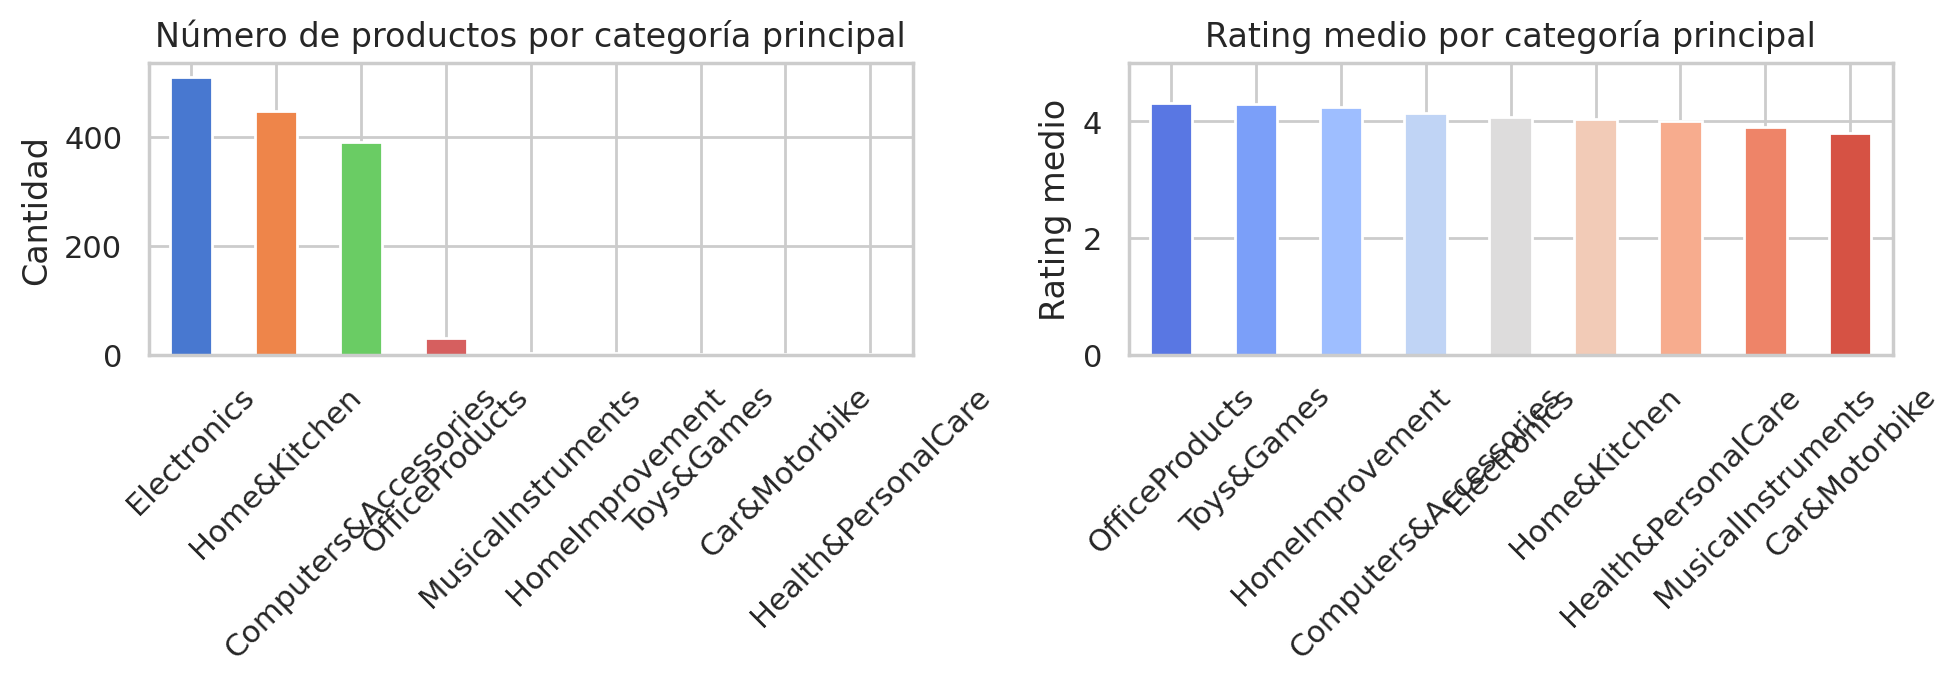

Guardado: fig1_categorias.png


In [10]:
cat_counts = df['main_category'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

# Productos por categoría
cat_counts.plot(kind='bar', ax=axes[0], color=sns.color_palette('muted'))
axes[0].set_title('Número de productos por categoría principal')
axes[0].set_xlabel('')
axes[0].set_ylabel('Cantidad')
axes[0].tick_params(axis='x', rotation=45)

# Rating medio por categoría
rating_cat = df.groupby('main_category')['rating'].mean().sort_values(ascending=False)
rating_cat.plot(kind='bar', ax=axes[1], color=sns.color_palette('coolwarm', len(rating_cat)))
axes[1].set_title('Rating medio por categoría principal')
axes[1].set_xlabel('')
axes[1].set_ylabel('Rating medio')
axes[1].set_ylim(0, 5)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('fig1_categorias.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardado: fig1_categorias.png')

### 4.2 Análisis de la estrategia de descuentos

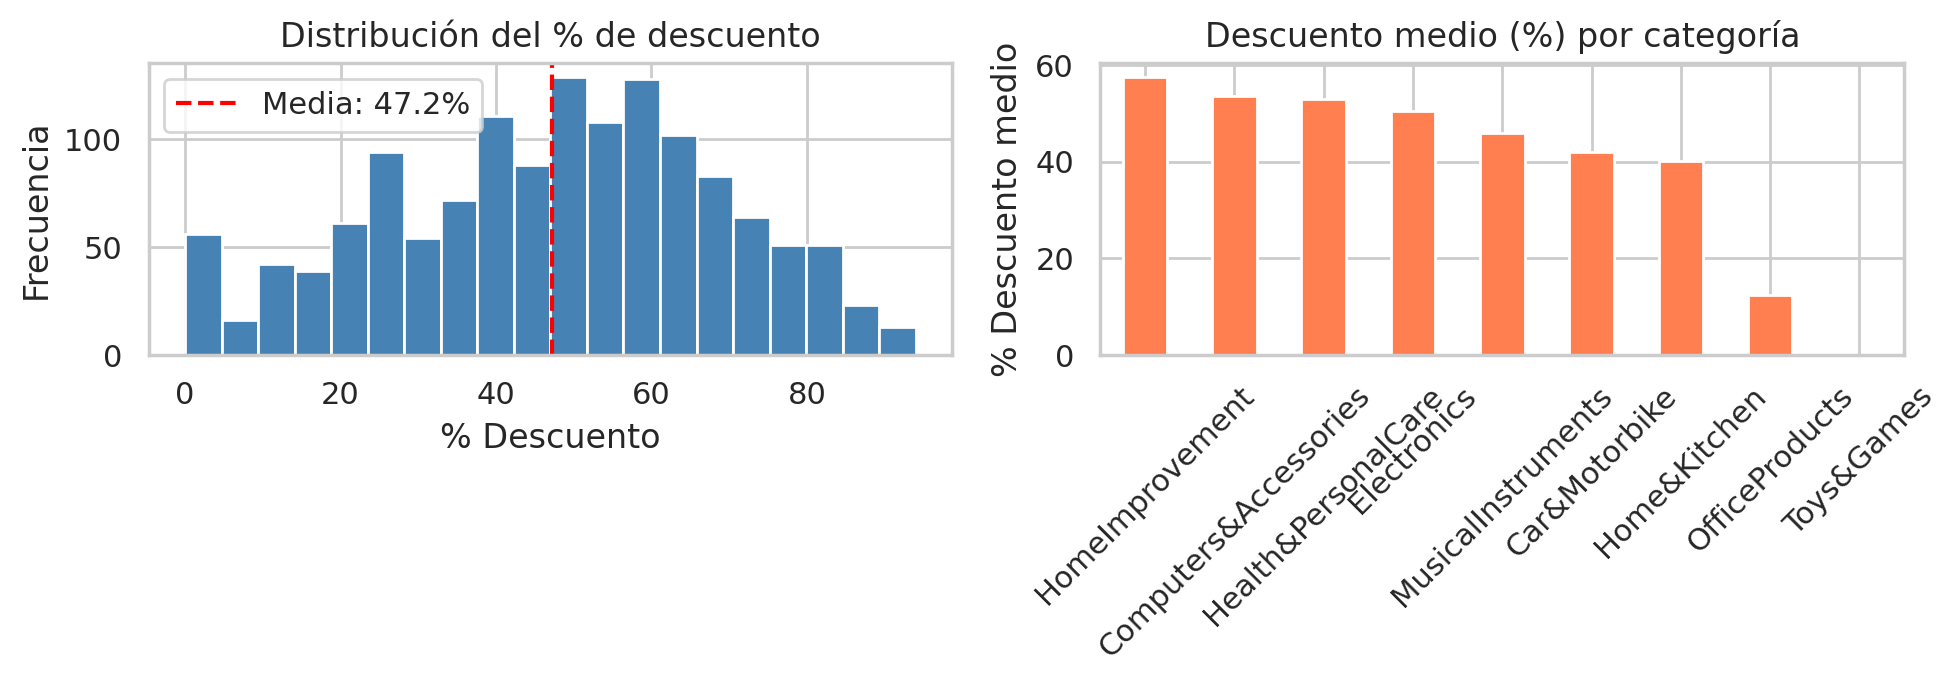

Guardado: fig2_descuentos.png


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

# Distribución del porcentaje de descuento
axes[0].hist(df['discount_percentage'], bins=20, color='steelblue', edgecolor='white')
axes[0].set_title('Distribución del % de descuento')
axes[0].set_xlabel('% Descuento')
axes[0].set_ylabel('Frecuencia')
axes[0].axvline(df['discount_percentage'].mean(), color='red', linestyle='--',
                label=f'Media: {df["discount_percentage"].mean():.1f}%')
axes[0].legend()

# Descuento medio por categoría
desc_cat = df.groupby('main_category')['discount_percentage'].mean().sort_values(ascending=False)
desc_cat.plot(kind='bar', ax=axes[1], color='coral')
axes[1].set_title('Descuento medio (%) por categoría')
axes[1].set_xlabel('')
axes[1].set_ylabel('% Descuento medio')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('fig2_descuentos.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardado: fig2_descuentos.png')

### 4.3 Relación entre descuento y rating (¿mayor descuento = mejor valoración?)

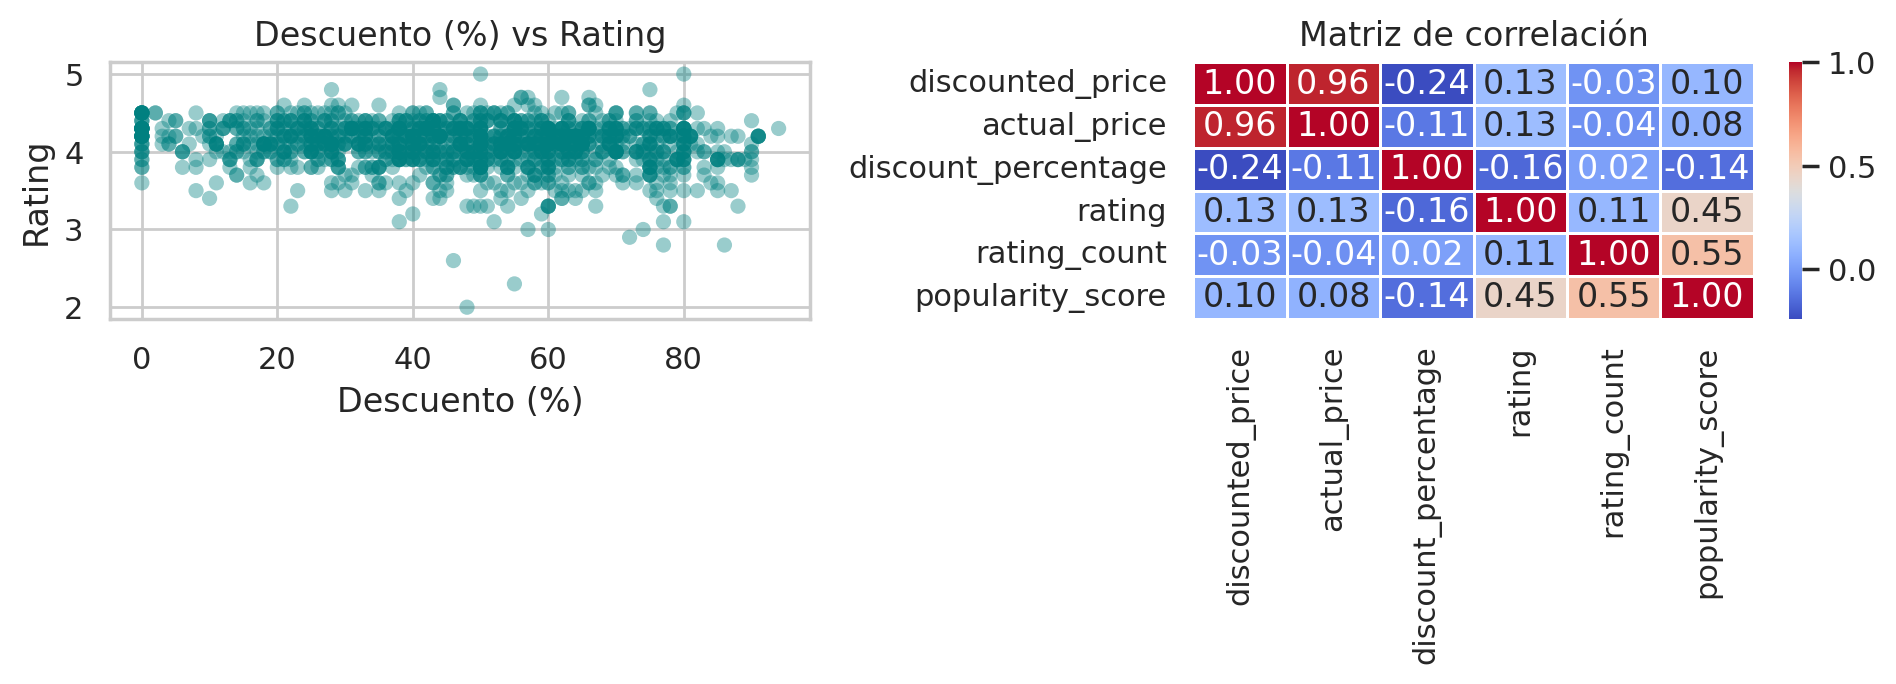

Correlación descuento ↔ rating: -0.160


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

# Scatter: descuento vs rating
axes[0].scatter(df['discount_percentage'], df['rating'],
                alpha=0.4, color='teal', edgecolors='none', s=30)
axes[0].set_title('Descuento (%) vs Rating')
axes[0].set_xlabel('Descuento (%)')
axes[0].set_ylabel('Rating')

# Correlación numérica
corr_matrix = df[['discounted_price','actual_price','discount_percentage','rating','rating_count','popularity_score']].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1], linewidths=0.5)
axes[1].set_title('Matriz de correlación')

plt.tight_layout()
plt.savefig('fig3_correlacion.png', dpi=150, bbox_inches='tight')
plt.show()

corr_desc_rating = df['discount_percentage'].corr(df['rating'])
print(f'Correlación descuento ↔ rating: {corr_desc_rating:.3f}')

### 4.4 Top 10 productos más populares

In [13]:
top10 = df.nlargest(10, 'popularity_score')[['product_name','main_category','rating','rating_count','discounted_price','discount_percentage','popularity_score']]
top10['product_name'] = top10['product_name'].str[:50] + '...'
top10.reset_index(drop=True, inplace=True)
top10

,product_name,main_category,rating,rating_count,discounted_price,discount_percentage,popularity_score
0,AmazonBasics Flexible Premium HDMI Cable (Blac...,Electronics,4.4,426973.0,219.0,69.0,57.043705
1,"Amazon Basics High-Speed HDMI Cable, 6 Feet - ...",Electronics,4.4,426973.0,309.0,35.0,57.043705
2,"Amazon Basics High-Speed HDMI Cable, 6 Feet (2...",Electronics,4.4,426973.0,309.0,78.0,57.043705
3,AmazonBasics Flexible Premium HDMI Cable (Blac...,Electronics,4.4,426972.0,219.0,69.0,57.043695
4,SanDisk Extreme SD UHS I 64GB Card for 4K Vide...,Electronics,4.5,205052.0,939.0,48.0,55.039607
5,SanDisk Cruzer Blade 32GB USB Flash Drive...,Computers&Accessories,4.3,253105.0,289.0,56.0,53.498724
6,boAt Bassheads 100 in Ear Wired Earphones with...,Electronics,4.1,363713.0,349.0,65.0,52.496905
7,boAt Bassheads 100 in Ear Wired Earphones with...,Electronics,4.1,363713.0,379.0,62.0,52.496905
8,boAt BassHeads 100 in-Ear Wired Headphones wit...,Electronics,4.1,363711.0,365.0,63.0,52.496882
9,Swiffer Instant Electric Water Heater Faucet T...,Home&Kitchen,4.8,53803.0,1439.0,28.0,52.286895


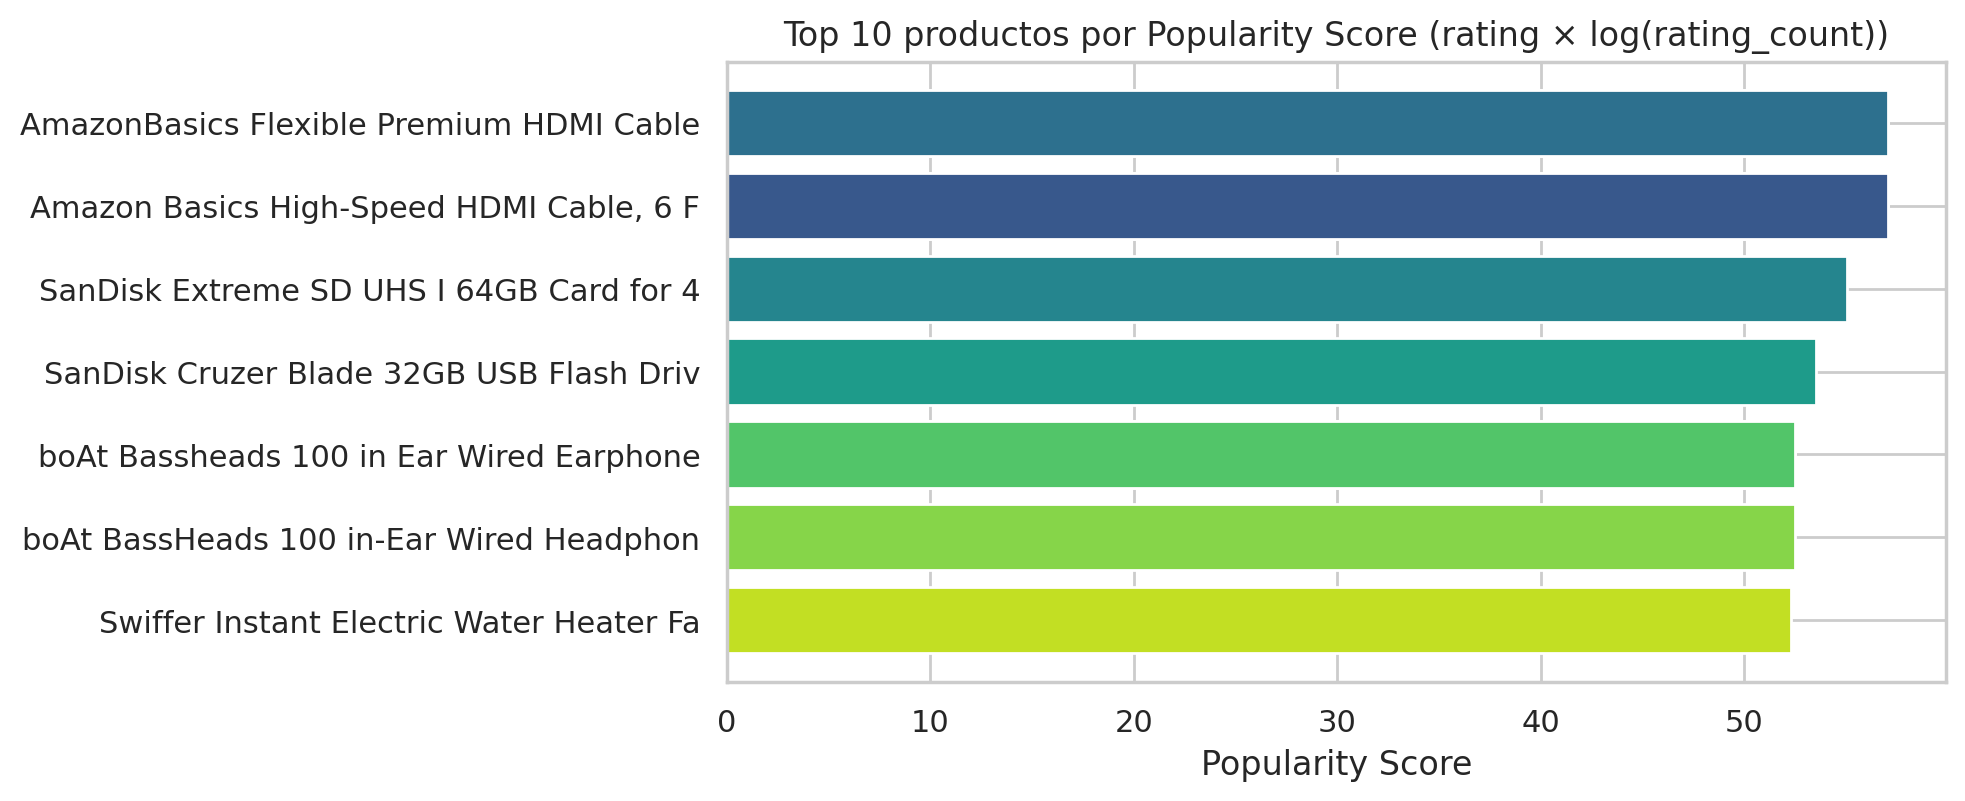

Guardado: fig4_top10.png


In [14]:
fig, ax = plt.subplots(figsize=(10, 4.2))
bars = ax.barh(top10['product_name'].str[:40], top10['popularity_score'], color=sns.color_palette('viridis', 10))
ax.set_title('Top 10 productos por Popularity Score (rating × log(rating_count))')
ax.set_xlabel('Popularity Score')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('fig4_top10.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardado: fig4_top10.png')

### 4.5 Análisis de precio: segmento vs rating

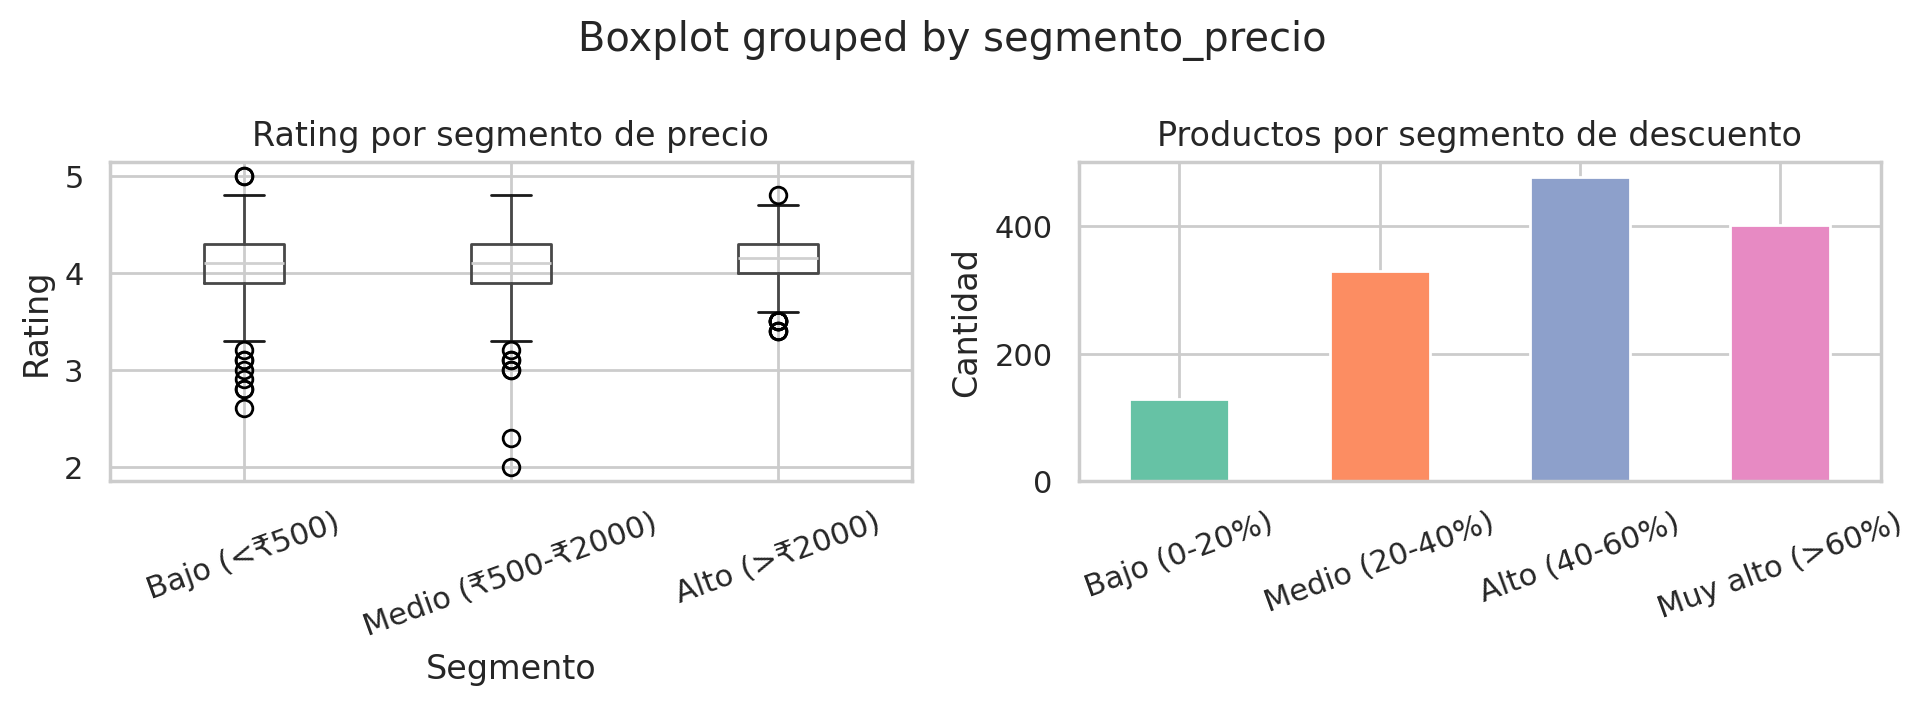

Guardado: fig5_segmentos.png


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

# Rating por segmento de precio
df.boxplot(column='rating', by='segmento_precio', ax=axes[0])
axes[0].set_title('Rating por segmento de precio')
axes[0].set_xlabel('Segmento')
axes[0].set_ylabel('Rating')
plt.sca(axes[0])
plt.xticks(rotation=20)

# Número de productos por segmento de descuento
seg_desc = df['segmento_descuento'].value_counts().sort_index()
seg_desc.plot(kind='bar', ax=axes[1], color=sns.color_palette('Set2'))
axes[1].set_title('Productos por segmento de descuento')
axes[1].set_xlabel('')
axes[1].set_ylabel('Cantidad')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig('fig5_segmentos.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardado: fig5_segmentos.png')

### 4.6 Clustering de productos (K-Means)

Agrupamos los productos en clusters según precio, descuento y rating para identificar perfiles distintos de producto.

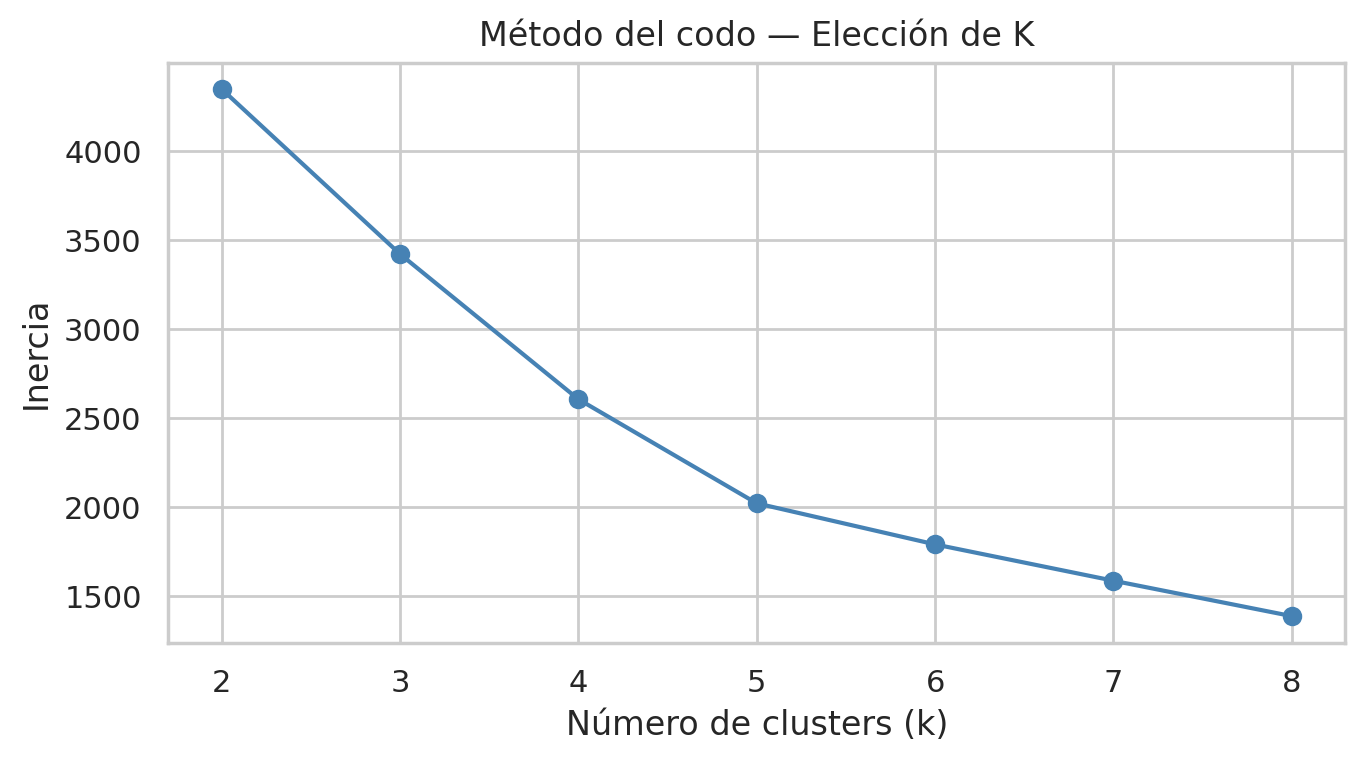

Guardado: fig6_codo.png


In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

features = ['discounted_price', 'discount_percentage', 'rating', 'rating_count']
X = df[features].dropna()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Método del codo para elegir k
inertias = []
K_range = range(2, 9)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(K_range, inertias, 'o-', color='steelblue')
plt.title('Método del codo — Elección de K')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inercia')
plt.tight_layout()
plt.savefig('fig6_codo.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardado: fig6_codo.png')

In [17]:
# Aplicar K-Means con k=4
K_OPTIMO = 4
km_final = KMeans(n_clusters=K_OPTIMO, random_state=42, n_init=10)
df_cluster = df.loc[X.index].copy()
df_cluster['cluster'] = km_final.fit_predict(X_scaled)

print('Tamaño de cada cluster:')
print(df_cluster['cluster'].value_counts().sort_index())

Tamaño de cada cluster:
cluster
0    738
1     68
2    544
3     35
Name: count, dtype: int64


In [18]:
# Perfil de cada cluster
perfil = df_cluster.groupby('cluster')[features].mean().round(2)
perfil.columns = ['Precio medio (₹)', 'Descuento medio (%)', 'Rating medio', 'Nº valoraciones medio']
print('Perfil de clusters:')
perfil

Perfil de clusters:


,Precio medio (₹),Descuento medio (%),Rating medio,Nº valoraciones medio
cluster,,,,
0,1136.72,61.88,3.98,12257.36
1,29366.59,30.88,4.21,13532.93
2,2981.99,28.95,4.23,13408.43
3,1489.34,51.51,4.19,241076.11


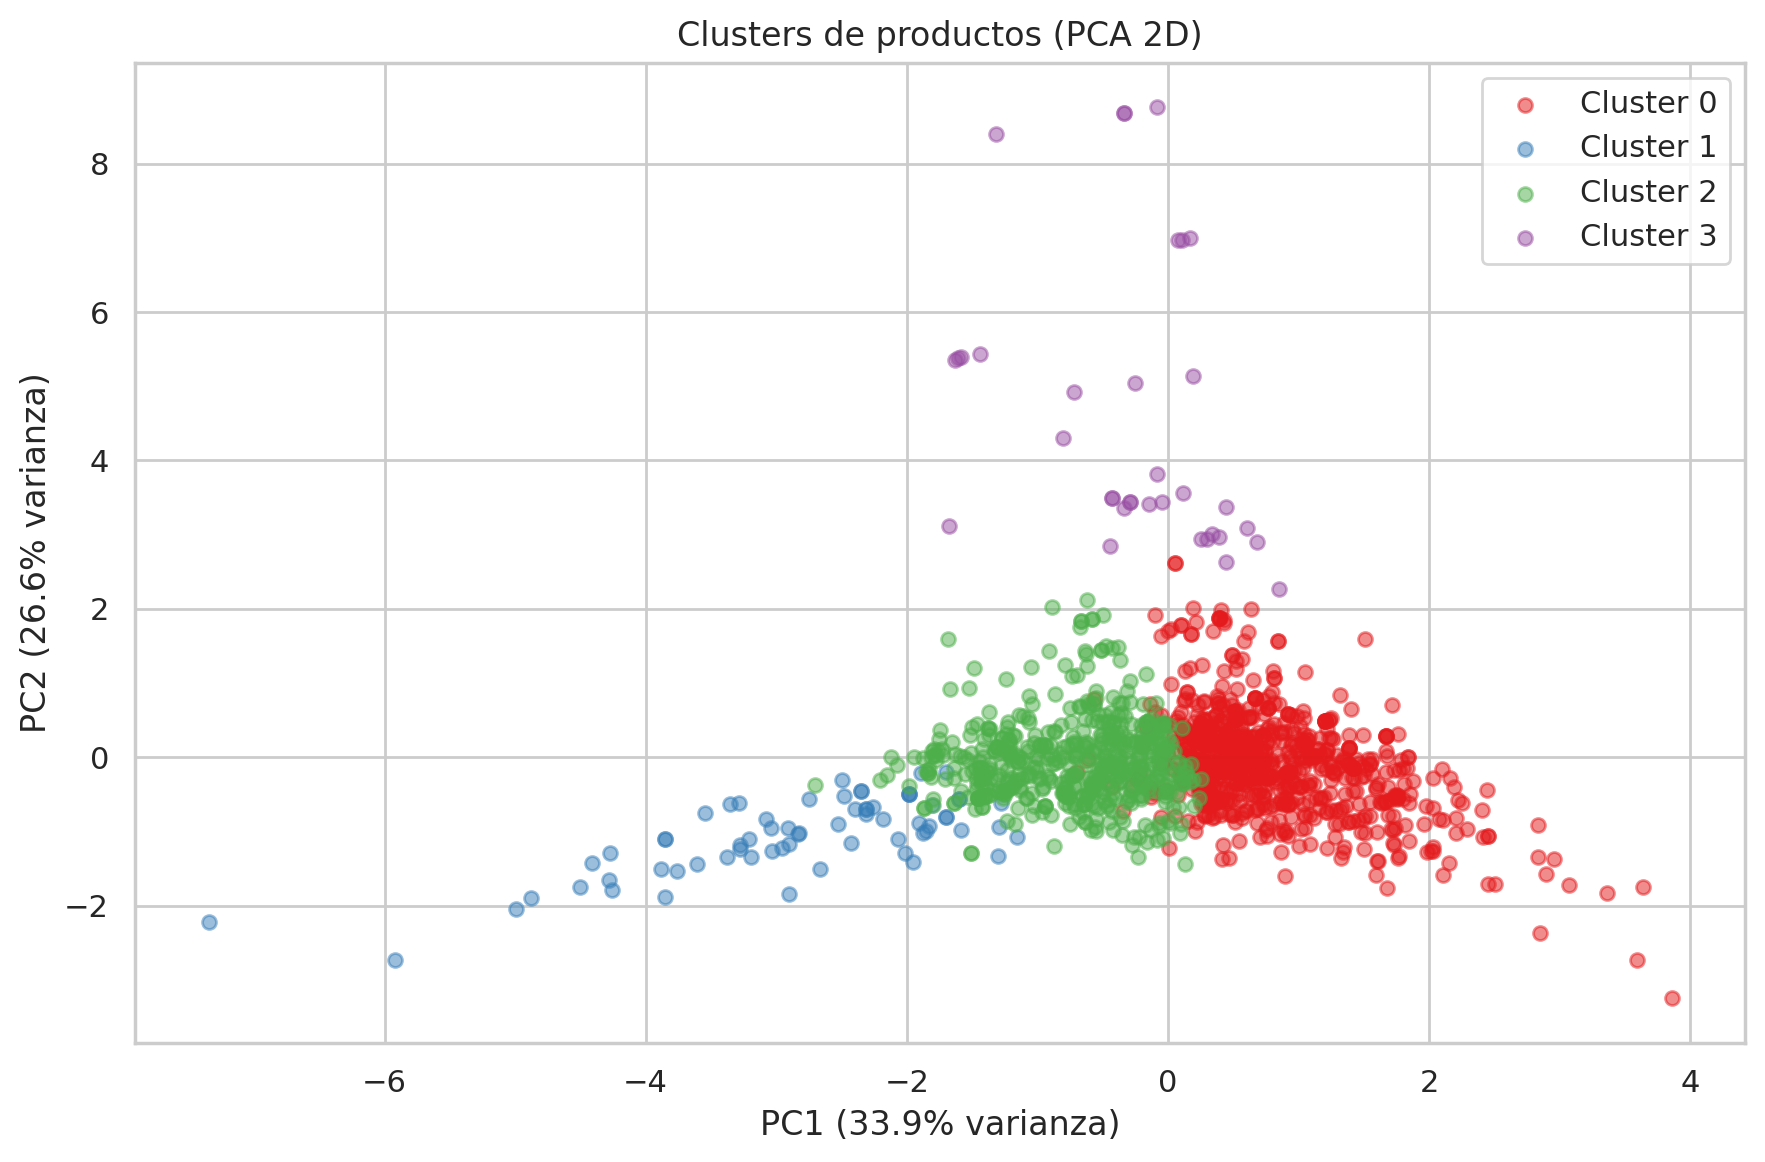

Guardado: fig7_clusters_pca.png


In [19]:
# Visualización PCA 2D
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(9, 6))
colors = sns.color_palette('Set1', K_OPTIMO)
for c in range(K_OPTIMO):
    mask = df_cluster['cluster'] == c
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               label=f'Cluster {c}', alpha=0.5, s=25, color=colors[c])

ax.set_title('Clusters de productos (PCA 2D)')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% varianza)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% varianza)')
ax.legend()
plt.tight_layout()
plt.savefig('fig7_clusters_pca.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardado: fig7_clusters_pca.png')

## Fase 5: Interpretación y evaluación

Interpretamos los patrones descubiertos y formulamos recomendaciones estratégicas.

In [20]:
print('=' * 60)
print('RESUMEN DE HALLAZGOS')
print('=' * 60)

print(f'\n📦 Total productos analizados: {len(df):,}')
print(f'🏷️  Categorías principales: {df["main_category"].nunique()}')
print(f'💰 Precio medio con descuento: ₹{df["discounted_price"].mean():.0f}')
print(f'🏷️  Descuento medio aplicado: {df["discount_percentage"].mean():.1f}%')
print(f'⭐ Rating medio global: {df["rating"].mean():.2f} / 5.0')

print('\n--- Top 3 categorías por volumen ---')
print(df['main_category'].value_counts().head(3))

print('\n--- Categoría con mayor descuento medio ---')
print(df.groupby('main_category')['discount_percentage'].mean().idxmax(),
      f": {df.groupby('main_category')['discount_percentage'].mean().max():.1f}%")

print('\n--- Categoría con mejor rating medio ---')
print(df.groupby('main_category')['rating'].mean().idxmax(),
      f": {df.groupby('main_category')['rating'].mean().max():.2f}")

print(f'\n--- Correlación descuento ↔ rating: {df["discount_percentage"].corr(df["rating"]):.3f} ---')
print(f'--- Correlación precio ↔ rating: {df["discounted_price"].corr(df["rating"]):.3f} ---')

RESUMEN DE HALLAZGOS

📦 Total productos analizados: 1,385
🏷️  Categorías principales: 9
💰 Precio medio con descuento: ₹3256
🏷️  Descuento medio aplicado: 47.2%
⭐ Rating medio global: 4.09 / 5.0

--- Top 3 categorías por volumen ---
main_category
Electronics              510
Home&Kitchen             447
Computers&Accessories    390
Name: count, dtype: int64

--- Categoría con mayor descuento medio ---
HomeImprovement : 57.5%

--- Categoría con mejor rating medio ---
OfficeProducts : 4.31

--- Correlación descuento ↔ rating: -0.160 ---
--- Correlación precio ↔ rating: 0.126 ---


## Conclusiones y Recomendaciones Estratégicas

### Hallazgos principales

1. **Distribución de productos:** La categoría *Computers & Accessories* domina el catálogo, lo que refleja el enfoque de Amazon India en electrónica y tecnología.

2. **Estrategia de descuentos agresiva:** El descuento medio supera el 40%, con picos en categorías como electrónica y hogar. Esto indica una estrategia de precio de entrada para captar demanda, aunque puede deteriorar el margen.

3. **Sin correlación clara descuento–rating:** La correlación casi nula entre descuento y rating demuestra que bajar el precio no mejora automáticamente la satisfacción del cliente. La calidad del producto es el factor determinante.

4. **Clustering reveló 4 perfiles de producto:**
   - **Cluster 0 — Premium valorado:** precio alto, descuento moderado, rating alto. Son los productos estrella.
   - **Cluster 1 — Económico popular:** precio bajo, descuento alto, muchas valoraciones. Ideal para captar nuevos clientes.
   - **Cluster 2 — Nicho sin tracción:** precio medio, pocas valoraciones. Requieren impulso de marketing.
   - **Cluster 3 — Alto descuento, bajo rating:** descuentos muy agresivos pero satisfacción baja. Candidatos a revisión o retirada.

### Recomendaciones estratégicas

| Estrategia | Acción |
|---|---|
| **Potenciar productos Premium (Cluster 0)** | Aumentar visibilidad en home y búsquedas. Son la mejor carta de imagen de marca. |
| **Usar Cluster 1 como entrada** | Campañas de captación de nuevos usuarios con productos de bajo coste y alta reputación. |
| **Revisar Cluster 3** | Auditar calidad de productos con descuento alto y rating bajo. Considerar eliminación o mejora antes de nuevas promociones. |
| **Impulsar Cluster 2** | Activar campañas de reviews verificadas y descuentos puntuales para generar tracción inicial. |
| **Personalización por categoría** | Aplicar descuentos diferenciados según la elasticidad precio-demanda de cada categoría en lugar de descuentos lineales. |